# LAB 03 — Naive Bayes: từ bằng chứng đến xác suất

**DNU Learning Analytics Lab**

- **Họ tên:** Nguyễn Văn An
- **MSSV:** 1871020172
- **Lớp:** DHKTPM18A

> **Câu hỏi trung tâm:** Nếu K-NN dự đoán bằng những sinh viên 'gần' nhất, Naive Bayes sẽ dự đoán cùng một sinh viên như thế nào bằng xác suất?

Lab 03 dùng **cùng bài toán, cùng feature, cùng target và cùng train/test split của Lab 02** để việc so sánh có ý nghĩa.

In [1]:
from pathlib import Path
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report
from nb_manual import compute_class_priors, gaussian_log_likelihood
DATA_PATH = Path('data/StudentPerformanceFactors.csv')
print('Environment ready! Dataset exists:', DATA_PATH.exists())

Environment ready! Dataset exists: True


# Mission 1 — Back to DNU case study

Tạo nhãn giảng dạy `Needs_Support = 1` nếu `Exam_Score < 65`, ngược lại là 0. Giữ đúng bài toán của Lab 02.

**Quan trọng:** không dùng `Exam_Score` làm feature vì sẽ gây target leakage.

**[TRẢ LỜI]**

**Vì sao đây là leakage?**
Nhãn `Needs_Support` được tạo trực tiếp từ `Exam_Score` theo quy tắc `Exam_Score < 65`. Nếu đưa `Exam_Score` vào tập feature, mô hình sẽ "nhìn thấy" chính thông tin mà nó cần dự đoán, dẫn đến độ chính xác ảo rất cao nhưng không có giá trị thực tế. Đây là dạng **target leakage** — feature rò rỉ thông tin của nhãn vào quá trình huấn luyện.

**Vì sao cần cùng train/test split như Lab 02?**
Để so sánh GaussianNB và K-NN có ý nghĩa, hai mô hình phải được đánh giá trên **cùng một tập test**. Nếu dùng split khác nhau, sự chênh lệch về kết quả có thể do sự khác biệt trong dữ liệu test, chứ không phản ánh thực sự năng lực của từng thuật toán. Dùng cùng `test_size=0.25, random_state=42, stratify=y` đảm bảo điều đó.

In [2]:
if not DATA_PATH.exists():
    raise FileNotFoundError('Run: python scripts/download_data.py')
df = pd.read_csv(DATA_PATH).copy()
df['Needs_Support'] = (df['Exam_Score'] < 65).astype(int)
feature_cols = ['Hours_Studied', 'Attendance', 'Previous_Scores', 'Sleep_Hours']
assert 'Exam_Score' not in feature_cols
model_df = df[feature_cols + ['Needs_Support']].dropna().copy()
X = model_df[feature_cols]
y = model_df['Needs_Support']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
print('Train:', X_train.shape, 'Test:', X_test.shape)
display(y_train.value_counts(normalize=True).rename('prior').to_frame())

Train: (4955, 4) Test: (1652, 4)


,prior
Needs_Support,
0,0.780222
1,0.219778


# Mission 2 — Prior first

Hoàn thiện `compute_class_priors(y)` trong `nb_manual.py`.

**[TRẢ LỜI]**

**`P(Needs_Support=1)` có ý nghĩa gì?**
`P(Needs_Support=1)` là xác suất tiên nghiệm (prior probability) — tỉ lệ sinh viên cần hỗ trợ trong tập huấn luyện, **trước khi quan sát bất kỳ feature nào**. Nó phản ánh "mức độ phổ biến" của lớp dương trong dữ liệu. Ví dụ, nếu `P(Needs_Support=1) = 0.30`, nghĩa là 30% sinh viên trong tập train có điểm dưới 65.

**Prior có phụ thuộc vào feature của sinh viên mới không?**
Không. Prior chỉ phụ thuộc vào **phân phối lớp trong tập huấn luyện**, hoàn toàn độc lập với feature của sinh viên mới cần dự đoán. Đây chính là ý nghĩa của "tiên nghiệm" — ta biết thông tin này trước khi nhìn thấy bất kỳ bằng chứng nào từ sinh viên mới.

In [3]:
try:
    priors_manual = compute_class_priors(y_train.to_numpy())
    print('Manual priors:', priors_manual)
    print('Pandas check:', y_train.value_counts(normalize=True).sort_index().to_dict())
except NotImplementedError as e:
    print('TODO in nb_manual.py ->', e)

Manual priors: {np.int64(0): 0.7802219979818366, np.int64(1): 0.21977800201816347}
Pandas check: {0: 0.7802219979818366, 1: 0.21977800201816347}


# Mission 3 — Gaussian evidence: model học gì?

Hoàn thiện `gaussian_log_likelihood(x, mean, var)` trong `nb_manual.py`, sau đó huấn luyện `GaussianNB`.

Quan sát `class_prior_`, `theta_`, `var_`.

**[TRẢ LỜI]**

**`theta_` và `var_` biểu diễn gì?**
- `theta_` là **mean (trung bình)** của từng feature cho từng lớp. Ví dụ, `theta_[1, 0]` là giá trị trung bình của `Hours_Studied` cho lớp `Needs_Support=1`.
- `var_` là **variance (phương sai)** của từng feature cho từng lớp. Nó đo mức độ phân tán của feature đó quanh mean trong mỗi lớp.

GaussianNB giả định mỗi feature tuân theo phân phối chuẩn (Gaussian) và chỉ lưu lại 2 tham số (mean, variance) cho mỗi cặp (feature, lớp). Đây là mô hình tham số rất gọn nhẹ.

**GaussianNB có lưu toàn bộ hàng xóm như K-NN không?**
Không. K-NN là mô hình **lazy learning** — nó lưu toàn bộ dữ liệu huấn luyện và chỉ tính toán khi có mẫu mới cần dự đoán. Ngược lại, GaussianNB là mô hình **tham số** — nó học và nén toàn bộ tập train thành các tham số (mean, variance, prior) và không cần giữ lại dữ liệu gốc. Điều này khiến GaussianNB nhanh hơn và tiết kiệm bộ nhớ hơn nhiều khi dự đoán.

In [4]:
gnb = GaussianNB()
gnb.fit(X_train, y_train)
print('Classes:', gnb.classes_)
print('Class priors:', gnb.class_prior_)
theta_df = pd.DataFrame(gnb.theta_, index=[f'class_{c}' for c in gnb.classes_], columns=feature_cols)
var_df = pd.DataFrame(gnb.var_, index=[f'class_{c}' for c in gnb.classes_], columns=feature_cols)
display(theta_df)
display(var_df)
sample0 = X_test.iloc[0]
attendance_idx = feature_cols.index('Attendance')
x_value = float(sample0['Attendance'])
for row_idx, class_label in enumerate(gnb.classes_):
    try:
        ll = gaussian_log_likelihood(x_value, float(gnb.theta_[row_idx, attendance_idx]), float(gnb.var_[row_idx, attendance_idx]))
        print(f'class={class_label}, Attendance log-likelihood={ll:.4f}')
    except NotImplementedError as e:
        print('TODO in nb_manual.py ->', e)
        break

Classes: [0 1]
Class priors: [0.780222 0.219778]


,Hours_Studied,Attendance,Previous_Scores,Sleep_Hours
class_0,21.129850,82.929384,76.102431,7.035954
class_1,15.768595,69.261708,71.642792,7.051423


,Hours_Studied,Attendance,Previous_Scores,Sleep_Hours
class_0,32.846047,113.289633,204.633585,2.193482
class_1,25.854625,56.782749,197.215837,2.162645


class=0, Attendance log-likelihood=-3.5614
class=1, Attendance log-likelihood=-3.2285


# Mission 4 — Evaluate beyond Accuracy

Đánh giá Accuracy, Precision, Recall, F1 và Confusion Matrix.

Đặc biệt chú ý **False Negative**: sinh viên thực tế cần hỗ trợ (`1`) nhưng model dự đoán không cần hỗ trợ (`0`).

**[TRẢ LỜI]**

**Vì sao chỉ nhìn Accuracy là chưa đủ?**

Accuracy chỉ đo tỉ lệ dự đoán đúng trên tổng số mẫu, nhưng không phân biệt được **loại lỗi** nào đang xảy ra. Trong bài toán này, dữ liệu có thể mất cân bằng (ví dụ: 80% sinh viên không cần hỗ trợ). Khi đó, một mô hình luôn dự đoán "không cần hỗ trợ" vẫn đạt accuracy 80% nhưng hoàn toàn vô dụng.

Quan trọng hơn, hai loại lỗi có **hậu quả không đối xứng**:
- **False Negative (FN):** Sinh viên cần hỗ trợ bị bỏ sót → hậu quả nghiêm trọng về học tập.
- **False Positive (FP):** Sinh viên không cần hỗ trợ bị gắn nhãn sai → lãng phí nguồn lực nhưng ít nguy hiểm hơn.

Vì vậy, trong case study này, **Recall** (tỉ lệ phát hiện đúng sinh viên cần hỗ trợ) quan trọng hơn Accuracy. Precision, F1 và Confusion Matrix giúp ta thấy toàn cảnh hơn về chất lượng mô hình.

,model,accuracy,precision,recall,f1,tn,fp,fn,tp
0,GaussianNB,0.878329,0.8,0.595041,0.682464,1235,54,147,216


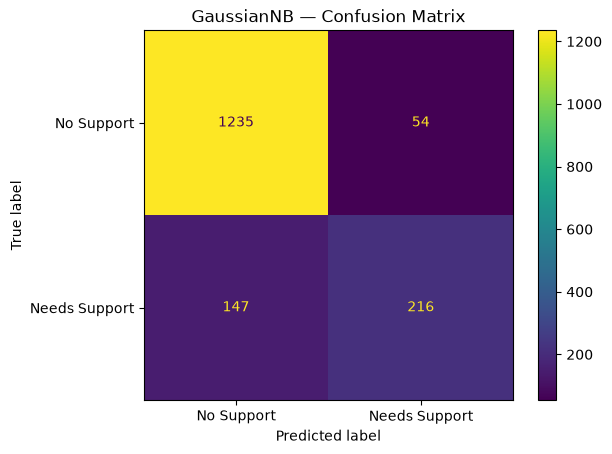

               precision    recall  f1-score   support

   No Support       0.89      0.96      0.92      1289
Needs Support       0.80      0.60      0.68       363

     accuracy                           0.88      1652
    macro avg       0.85      0.78      0.80      1652
 weighted avg       0.87      0.88      0.87      1652



In [5]:
def evaluate_binary(name, y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    return {'model': name, 'accuracy': accuracy_score(y_true,y_pred), 'precision': precision_score(y_true,y_pred,zero_division=0), 'recall': recall_score(y_true,y_pred,zero_division=0), 'f1': f1_score(y_true,y_pred,zero_division=0), 'tn':tn, 'fp':fp, 'fn':fn, 'tp':tp}
nb_pred = gnb.predict(X_test)
nb_result = evaluate_binary('GaussianNB', y_test, nb_pred)
display(pd.DataFrame([nb_result]))
ConfusionMatrixDisplay.from_predictions(y_test, nb_pred, display_labels=['No Support','Needs Support'])
plt.title('GaussianNB — Confusion Matrix')
plt.show()
print(classification_report(y_test, nb_pred, target_names=['No Support','Needs Support'], zero_division=0))

# Mission 5 — Explain one student

Chọn một sample trong `X_test`, xem `predict_proba()` và thử tính log-score từ log prior + Gaussian log-likelihood của từng feature.

> Đây không phải feature importance; ta đang xem likelihood cho một dự đoán cụ thể.

**[TRẢ LỜI]**

**Model dự đoán lớp nào?**
Model dự đoán lớp có tổng log-score cao hơn. Cụ thể, lớp được chọn là lớp mà `log_prior + tổng Gaussian log-likelihood của tất cả feature` đạt giá trị lớn hơn.

**Bằng chứng nào có vẻ nghiêng nhiều hơn về lớp đó?**
Các feature có log-likelihood chênh lệch lớn giữa hai lớp sẽ đóng vai trò "bằng chứng" mạnh nhất. Ví dụ, nếu sinh viên có `Hours_Studied` cao hơn nhiều so với mean của lớp `Needs_Support=1` nhưng gần với mean của lớp `Needs_Support=0`, thì feature này nghiêng mạnh về lớp 0. Điểm số `total_log_score` cao hơn ở lớp nào thì mô hình dự đoán lớp đó, và kết quả `Manual argmax` phải khớp với kết quả của sklearn.

In [6]:
student_x = X_test.iloc[[0]]
display(student_x)
pred_class = int(gnb.predict(student_x)[0])
proba = gnb.predict_proba(student_x)[0]
for cls, p in zip(gnb.classes_, proba):
    print(f'P(class={cls} | X) = {p:.6f}')
try:
    x_arr = student_x.iloc[0].to_numpy(dtype=float)
    rows = []
    for i, cls in enumerate(gnb.classes_):
        log_prior = math.log(float(gnb.class_prior_[i]))
        feature_ll = [gaussian_log_likelihood(float(x_arr[j]), float(gnb.theta_[i,j]), float(gnb.var_[i,j])) for j in range(len(feature_cols))]
        rows.append({'class': int(cls), 'log_prior': log_prior, **{f'll_{f}':v for f,v in zip(feature_cols,feature_ll)}, 'total_log_score': log_prior + sum(feature_ll)})
    score_df = pd.DataFrame(rows)
    display(score_df)
    print('Manual argmax:', int(score_df.loc[score_df.total_log_score.idxmax(),'class']), 'sklearn:', pred_class)
except NotImplementedError as e:
    print('TODO in nb_manual.py ->', e)

,Hours_Studied,Attendance,Previous_Scores,Sleep_Hours
3214,24,75,94,7


P(class=0 | X) = 0.921193
P(class=1 | X) = 0.078807


,class,log_prior,ll_Hours_Studied,ll_Attendance,ll_Previous_Scores,ll_Sleep_Hours,total_log_score
0,0,-0.248177,-2.790254,-3.561410,-4.362223,-1.311978,-12.274042
1,1,-1.515137,-3.855510,-3.228502,-4.828341,-1.305216,-14.732707


Manual argmax: 0 sklearn: 0


# Mission 6 — K-NN vs Naive Bayes

So sánh hai cách suy luận trên **cùng test set**. K-NN tham chiếu dùng `K=5`, Euclidean và `StandardScaler`.

**[TRẢ LỜI]**

**Tìm ít nhất 3 sample hai model dự đoán khác nhau và giải thích vì sao chúng có thể bất đồng:**

Hai mô hình bất đồng vì cơ chế suy luận khác nhau căn bản:

1. **Sample có feature gần ranh giới quyết định (boundary cases):** K-NN phụ thuộc vào 5 hàng xóm gần nhất trong không gian Euclidean. Nếu 3/5 hàng xóm thuộc lớp 0, K-NN dự đoán 0. Nhưng GaussianNB có thể dự đoán 1 nếu giá trị feature của mẫu đó gần với phân phối Gaussian của lớp 1 hơn, kể cả khi các hàng xóm gần nhất thuộc lớp 0.

2. **Sample là outlier cục bộ:** Nếu một sinh viên có `Hours_Studied` rất cao (outlier) nhưng nằm trong vùng dày đặc của lớp cần hỗ trợ, K-NN sẽ bị kéo về phía lớp xung quanh. GaussianNB nhìn vào mean và variance — nếu `Hours_Studied` cao có log-likelihood lớn hơn ở lớp 0, nó sẽ dự đoán 0 bất kể hàng xóm.

3. **Tác động của giả định độc lập:** GaussianNB giả định các feature **độc lập có điều kiện** với nhau. Trong thực tế, `Hours_Studied` và `Attendance` có thể tương quan cao. K-NN không có giả định này — nó đo khoảng cách trong không gian feature chung, tự nhiên nắm bắt được tương quan. Với những mẫu có pattern tương quan đặc biệt, hai mô hình sẽ bất đồng.

In [7]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)
knn = KNeighborsClassifier(n_neighbors=5, metric='euclidean')
knn.fit(X_train_scaled, y_train)
knn_pred = knn.predict(X_test_scaled)
knn_result = evaluate_binary('KNN k=5 scaled', y_test, knn_pred)
display(pd.DataFrame([nb_result, knn_result])[['model','accuracy','precision','recall','f1','fn','fp']])
comparison = X_test.reset_index(drop=True).copy()
comparison['Actual'] = y_test.reset_index(drop=True)
comparison['NB_Pred'] = nb_pred
comparison['KNN_Pred'] = knn_pred
comparison['Same'] = comparison['NB_Pred'] == comparison['KNN_Pred']
disagreements = comparison[~comparison['Same']].copy()
print('Number of disagreements:', len(disagreements))
display(disagreements.head(10))

,model,accuracy,precision,recall,f1,fn,fp
0,GaussianNB,0.878329,0.800000,0.595041,0.682464,147,54
1,KNN k=5 scaled,0.860775,0.698507,0.644628,0.670487,129,101


Number of disagreements: 135


,Hours_Studied,Attendance,Previous_Scores,Sleep_Hours,Actual,NB_Pred,KNN_Pred,Same
24,13,71,98,7,1,1,0,False
26,12,77,64,7,1,1,0,False
33,22,76,66,7,0,0,1,False
35,22,64,68,8,0,0,1,False
36,21,62,86,6,0,0,1,False
37,27,62,75,5,0,0,1,False
47,18,61,96,6,1,1,0,False
71,18,68,82,6,0,1,0,False
73,16,67,98,8,1,1,0,False
76,21,62,94,7,1,0,1,False


# Transfer Challenge — Naive Bayes không chỉ dành cho Student Performance

Pipeline: `Text → CountVectorizer → word counts → MultinomialNB → Topic`.

**[TRẢ LỜI]** Vì sao văn bản đếm từ dùng MultinomialNB thay vì GaussianNB?

GaussianNB giả định feature tuân theo **phân phối chuẩn (Gaussian)** — phù hợp cho dữ liệu liên tục như số giờ học, điểm số. Tuy nhiên, dữ liệu đếm từ (word counts) sau CountVectorizer là các **số nguyên không âm, rời rạc**, phân phối lệch phải, rất không giống Gaussian.

**MultinomialNB** được thiết kế chính xác cho dữ liệu đếm: nó mô hình hóa xác suất xuất hiện của từng từ trong một lớp theo phân phối đa thức. Với bộ từ vựng lớn và hầu hết các giá trị là 0 (sparse matrix), MultinomialNB phù hợp tự nhiên và hiệu quả hơn GaussianNB rất nhiều.

Mặc định `RUN_TRANSFER=False` để GitHub Actions không phụ thuộc vào tải 20 Newsgroups.

In [8]:
RUN_TRANSFER = False
if RUN_TRANSFER:
    from sklearn.datasets import fetch_20newsgroups
    categories = ['comp.graphics','rec.sport.baseball','sci.space','talk.politics.misc']
    train_text = fetch_20newsgroups(subset='train', categories=categories, remove=('headers','footers','quotes'))
    test_text = fetch_20newsgroups(subset='test', categories=categories, remove=('headers','footers','quotes'))
    vectorizer = CountVectorizer(stop_words='english', max_features=10000)
    X_text_train = vectorizer.fit_transform(train_text.data)
    X_text_test = vectorizer.transform(test_text.data)
    mnb = MultinomialNB(alpha=1.0)
    mnb.fit(X_text_train, train_text.target)
    text_pred = mnb.predict(X_text_test)
    print('20 Newsgroups accuracy:', accuracy_score(test_text.target, text_pred))
else:
    print('Transfer Challenge skipped. Set RUN_TRANSFER=True to run it.')

Transfer Challenge skipped. Set RUN_TRANSFER=True to run it.


# Final — Model Reflection Card

## 1. Prior, likelihood và posterior khác nhau thế nào?

- **Prior** `P(C)`: xác suất của lớp C **trước khi** quan sát feature. Được tính từ tỉ lệ phân phối lớp trong tập train. Ví dụ: 30% sinh viên cần hỗ trợ → P(Needs_Support=1) = 0.30.
- **Likelihood** `P(X|C)`: xác suất quan sát được feature X **nếu biết** lớp là C. GaussianNB giả định mỗi feature là Gaussian và tính `P(x_j | C)` từ mean và variance của feature đó trong lớp C.
- **Posterior** `P(C|X)`: xác suất lớp C **sau khi** quan sát feature X. Theo Bayes: `P(C|X) ∝ P(C) × ∏ P(x_j|C)`. Đây là thứ mô hình thực sự dự đoán — lớp nào có posterior cao hơn được chọn.

## 2. GaussianNB thực sự học gì từ tập train?

GaussianNB học **3 loại thống kê** từ tập train:
1. **Class prior** `P(C)`: tỉ lệ mẫu của mỗi lớp.
2. **Mean** `θ[c,j]`: giá trị trung bình của feature j trong lớp c.
3. **Variance** `σ²[c,j]`: phương sai của feature j trong lớp c.

Với các tham số này, GaussianNB xây dựng một phân phối Gaussian cho từng feature trong từng lớp và dùng nó để tính likelihood khi dự đoán mẫu mới. Mô hình **không lưu dữ liệu gốc** — chỉ lưu các tham số tóm tắt.

## 3. Trong case study `Needs_Support`, lỗi nào đáng chú ý hơn?

**False Negative (FN)** đáng chú ý hơn: đây là trường hợp sinh viên **thực sự cần hỗ trợ** nhưng mô hình dự đoán là không cần. Những sinh viên này sẽ không nhận được sự can thiệp kịp thời, dẫn đến nguy cơ học tập tiếp tục kém. Chi phí của việc bỏ sót một sinh viên cần hỗ trợ cao hơn nhiều so với việc gắn nhãn sai cho một sinh viên không cần hỗ trợ (False Positive). Vì vậy, trong bài toán này, **Recall** là metric quan trọng nhất cần tối ưu.

## 4. Vì sao `Exam_Score` không được dùng làm feature?

`Exam_Score` không được dùng làm feature vì nhãn `Needs_Support` được định nghĩa trực tiếp từ nó: `Needs_Support = 1 nếu Exam_Score < 65`. Đưa `Exam_Score` vào feature sẽ tạo ra **target leakage** — mô hình có thể học một quy tắc đơn giản như "nếu Exam_Score < 65 thì dự đoán 1" và đạt accuracy gần 100% mà không học được bất kỳ pattern thực sự nào từ các feature có ý nghĩa giáo dục. Kết quả sẽ không khái quát hóa được cho tình huống thực tế khi chưa biết điểm thi.

## 5. K-NN và GaussianNB khác nhau ở cách ra quyết định như thế nào?

| Tiêu chí | K-NN | GaussianNB |
|----------|------|------------|
| **Nguyên lý** | Dựa trên khoảng cách | Dựa trên xác suất Bayes |
| **Huấn luyện** | Lưu toàn bộ dữ liệu (lazy) | Học tham số (mean, var, prior) |
| **Dự đoán** | Tìm K hàng xóm gần nhất → bỏ phiếu | Tính posterior cho từng lớp → chọn max |
| **Giả định** | Không có giả định phân phối | Feature độc lập có điều kiện, Gaussian |
| **Bộ nhớ** | O(n) — tăng theo dữ liệu | O(C×F) — hằng số |
| **Tốc độ dự đoán** | Chậm (tính khoảng cách) | Nhanh (tính công thức) |

## 6. Vì sao 20 Newsgroups dùng MultinomialNB thay vì GaussianNB?

Dữ liệu văn bản sau CountVectorizer là **word counts** — số nguyên không âm, rời rạc, phân phối lệch mạnh (hầu hết là 0). GaussianNB giả định phân phối chuẩn (liên tục, đối xứng) — hoàn toàn không phù hợp với bản chất này. MultinomialNB được xây dựng cho phân phối đa thức, mô hình hóa xác suất xuất hiện của từng từ trong một document thuộc lớp c. Nó xử lý hiệu quả sparse matrix và capture ngữ nghĩa đếm từ một cách chính xác về mặt xác suất.

## 7. Một câu chốt
> Dataset không đổi nhưng dự đoán có thể thay đổi vì...

...mỗi thuật toán có **"thấu kính" quan sát khác nhau**: K-NN nhìn vào không gian khoảng cách và hỏi "ai giống mẫu này nhất?", còn Naive Bayes nhìn vào không gian xác suất và hỏi "bằng chứng này nghiêng về lớp nào nhiều hơn?" — hai góc nhìn hợp lý nhưng khác nhau căn bản dẫn đến những dự đoán khác nhau trên cùng một dữ liệu, đặc biệt ở các mẫu nằm gần ranh giới quyết định.

## Trước khi push
```bash
python scripts/download_data.py
python tests/check_lab03.py
python -m pytest -q tests/test_nb_manual.py
git add .
git commit -m "Complete Lab 03 Naive Bayes"
git push
```